# A5 — Application Demo (Drug-Discovery Style): A Quantum Generative Model

Vivekananda GN

In the KRAS drug-discovery study, a **Quantum Circuit Born Machine (QCBM)** learned a distribution over a molecule representation and *generated* new candidates.
Here the circuit learns to generate bit patterns ("fingerprints") resembling a training set.

**Tool:** Qibo + SciPy.

In [ ]:
# Run once (Google Colab or local). Qibo is an open-source quantum framework: https://qibo.science
!pip install -q qibo scikit-learn matplotlib scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 369.5/369.5 kB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 347.2/347.2 kB 25.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 33.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 29.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 20.1 MB/s eta 0:00:00


In [ ]:
import numpy as np, matplotlib.pyplot as plt
from qibo import Circuit, gates, set_backend
set_backend("numpy")           # plain CPU simulator, works everywhere
np.set_printoptions(precision=3, suppress=True)
from scipy.optimize import minimize
from collections import Counter

[Qibo 0.3.5|INFO|2026-10-03 04:44:11]: Using numpy backend on /CPU:0
INFO:qibo.config:Using numpy backend on /CPU:0


## 4.1 Make a toy 'training set' of 4-bit fingerprints
Pretend each bit means a molecular feature (e.g. has ring, has halogen …). Our 'known active molecules' favour a few patterns.

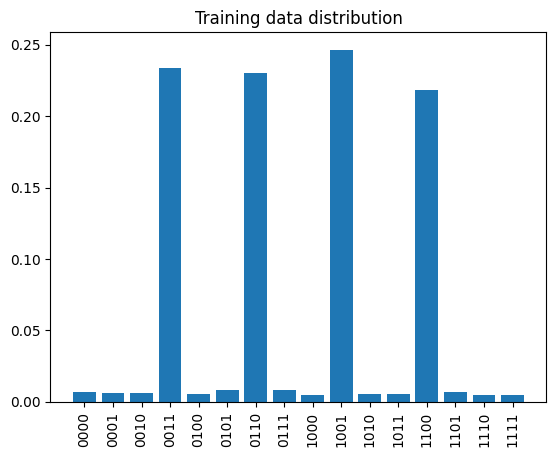

In [ ]:
rng = np.random.default_rng(0)
favoured = ['0011', '0110', '1100', '1001']                 # pretend: patterns seen in active molecules
data = [rng.choice(favoured) if rng.random() < 0.9 else format(rng.integers(16), '04b') for _ in range(2000)]
cnt = Counter(data); target = np.array([cnt.get(format(i, '04b'), 0) for i in range(16)], float); target /= target.sum()
labels = [format(i, '04b') for i in range(16)]
plt.bar(labels, target); plt.xticks(rotation=90); plt.title('Training data distribution'); plt.show()

## 4.2 The QCBM: a circuit whose measurement probabilities are the model

final KL divergence: 0.001  (start: 0.576)  parameters: 16


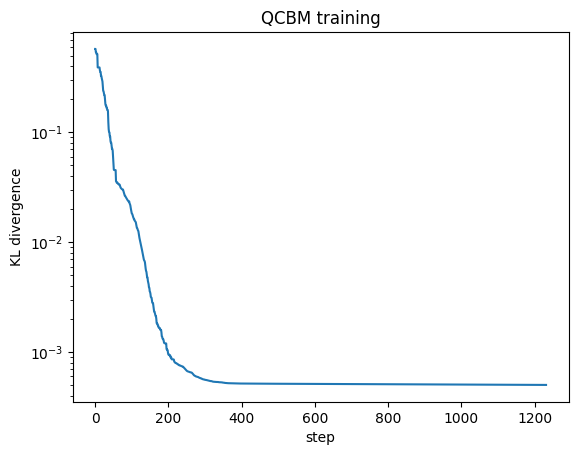

In [ ]:
NQ, L = 4, 4
def qcbm_probs(theta):
    th = theta.reshape(L, NQ)
    c = Circuit(NQ)
    for l in range(L):
        for q in range(NQ): c.add(gates.RY(q, th[l, q]))
        for q in range(NQ): c.add(gates.CNOT(q, (q+1) % NQ))
    return c().probabilities()

def kl(theta):
    p = np.clip(qcbm_probs(theta), 1e-9, 1); t = np.clip(target, 1e-9, 1)
    return np.sum(t*np.log(t/p))            # how different is the model from the data?

th0 = np.random.default_rng(1).uniform(0, 2*np.pi, L*NQ)
hist = []
res = minimize(kl, th0, method='COBYLA', options={'maxiter': 1500}, callback=lambda t: hist.append(kl(t)))
print(f"final KL divergence: {res.fun:.3f}  (start: {hist[0]:.3f})  parameters: {th0.size}")
plt.plot(hist); plt.yscale('log'); plt.xlabel('step'); plt.ylabel('KL divergence'); plt.title('QCBM training'); plt.show()

## 4.3 Compare learned vs. target, then *generate new candidates*

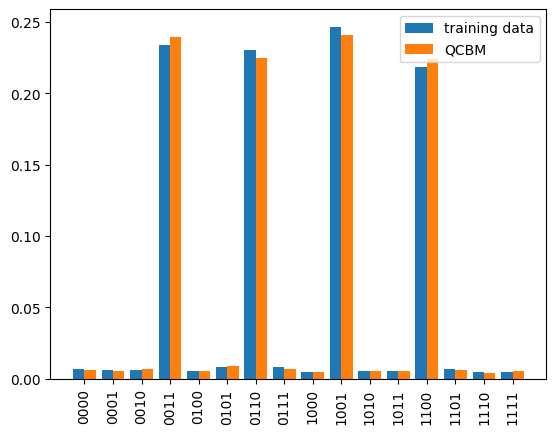

Top generated patterns: [('0011', 243), ('0110', 231), ('1100', 223), ('1001', 221), ('0010', 11), ('0000', 11)]
fraction of generated samples that are in the favoured set: 0.92


In [ ]:
p = qcbm_probs(res.x)
x = np.arange(16)
plt.bar(x-0.2, target, 0.4, label='training data'); plt.bar(x+0.2, p, 0.4, label='QCBM'); plt.xticks(x, labels, rotation=90); plt.legend(); plt.show()

samples = np.random.default_rng(5).choice(16, size=1000, p=p/p.sum())
gen = Counter(format(s, '04b') for s in samples)
seen = set(favoured)
print("Top generated patterns:", gen.most_common(6))
print(f"fraction of generated samples that are in the favoured set: {sum(v for k,v in gen.items() if k in seen)/1000:.2f}")

## 4.4 Observations
In the real KRAS work the QCBM served as a **prior** feeding a classical LSTM generator; candidates were then filtered, synthesised and tested in the lab. The study did *not* show the quantum part beats the best classical generators.

**Discussion:**
1. Increase `L` to 1 and 6. Does the KL get better or worse? Why might deeper circuits be harder to train?
2. Replace the training set with 5 qubits (32 patterns). How does the optimiser struggle?
3. What would you need before claiming a *quantum advantage* here? (Fair classical baselines, repeated seeds, real data.)